In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import xgboost as xgb
import seaborn as sns


from sklearn.metrics import mean_squared_error


import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')

In [2]:
df=pd.read_csv(r"C:\Users\SOLOMON\Downloads\Telegram Desktop\weatherdata.csv")

In [3]:
df

,Date,Longitude,Latitude,Elevation,Max Temperature,Min Temperature,Wind,Relative Humidity,Solar,Precipitation
0,1/1/79,37.5,6.71292,1494,30.713,11.719,1.595418,0.418255,23.386395,0.000000
1,1/2/79,37.5,6.71292,1494,30.872,10.407,1.726672,0.432899,25.572441,0.000000
2,1/3/79,37.5,6.71292,1494,28.579,10.795,1.870545,0.456901,25.568213,0.000000
3,1/4/79,37.5,6.71292,1494,29.383,10.712,1.704374,0.463286,25.659900,0.000000
4,1/5/79,37.5,6.71292,1494,30.837,9.487,1.719667,0.394840,25.737013,0.000000
...,...,...,...,...,...,...,...,...,...,...
12982,7/27/14,37.5,6.71292,1494,21.351,15.630,1.123813,0.898494,15.266439,33.345219
12983,7/28/14,37.5,6.71292,1494,25.326,15.266,1.128937,0.840943,21.724500,11.767387
12984,7/29/14,37.5,6.71292,1494,23.138,13.402,1.297933,0.799027,18.358496,1.153566
12985,7/30/14,37.5,6.71292,1494,25.306,12.483,1.690213,0.739780,23.324918,0.418854


In [4]:
df = df.drop(
    columns=['Longitude', 'Latitude', 'Elevation'])

In [5]:
df = df.set_index('Date')

In [6]:
df.index = pd.to_datetime(df.index, dayfirst=True)

C:\Users\SOLOMON\AppData\Local\Temp\ipykernel_28832\3764146352.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df.index = pd.to_datetime(df.index, dayfirst=True)


In [7]:
df

,Max Temperature,Min Temperature,Wind,Relative Humidity,Solar,Precipitation
Date,,,,,,
1979-01-01,30.713,11.719,1.595418,0.418255,23.386395,0.000000
1979-02-01,30.872,10.407,1.726672,0.432899,25.572441,0.000000
1979-03-01,28.579,10.795,1.870545,0.456901,25.568213,0.000000
1979-04-01,29.383,10.712,1.704374,0.463286,25.659900,0.000000
1979-05-01,30.837,9.487,1.719667,0.394840,25.737013,0.000000
...,...,...,...,...,...,...
2014-07-27,21.351,15.630,1.123813,0.898494,15.266439,33.345219
2014-07-28,25.326,15.266,1.128937,0.840943,21.724500,11.767387
2014-07-29,23.138,13.402,1.297933,0.799027,18.358496,1.153566


<Axes: title={'center': 'Weather Forcast'}, xlabel='Date'>

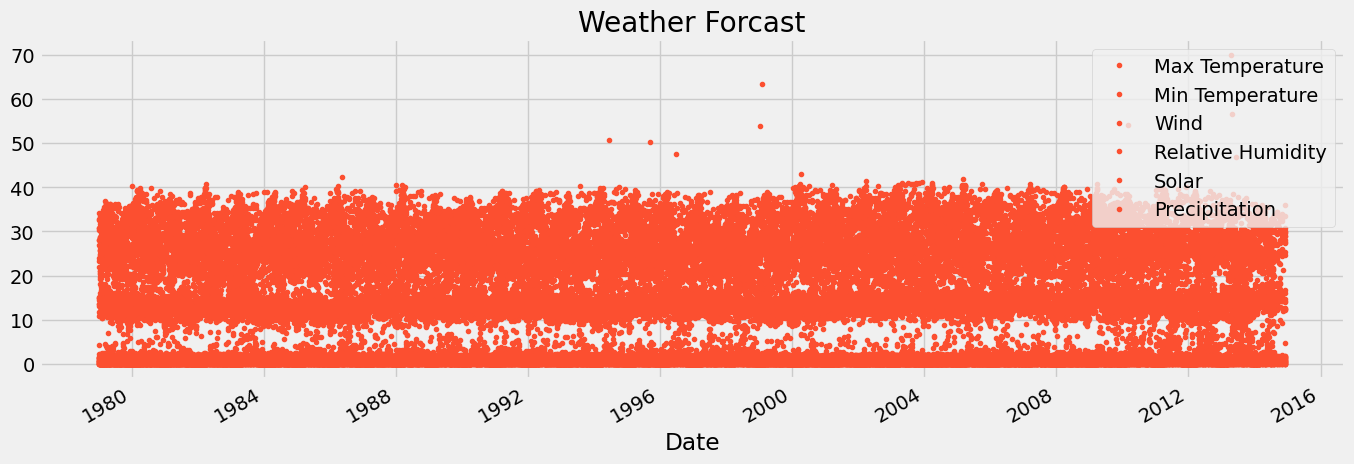

In [9]:

color_pallete = sns.color_palette()
df.plot(style='.', figsize=(15,5), color= color_pallete[1], title="Weather Forcast")

In [10]:
train = df.loc[df.index<= '2014-07-01']
test = df.loc[df.index >= '2014-07-02']

In [11]:
len(train), len(test)

(12927, 60)

In [27]:
tr=train["Precipitation"]
te=test["Precipitation"]

Date
1979-01-01    0.000000
1979-02-01    0.000000
1979-03-01    0.000000
1979-04-01    0.000000
1979-05-01    0.000000
                ...   
2014-02-07    0.514984
2014-03-07    0.175095
2014-04-07    0.000000
2014-05-07    0.000000
2014-06-07    4.202273
Name: Precipitation, Length: 12927, dtype: float64

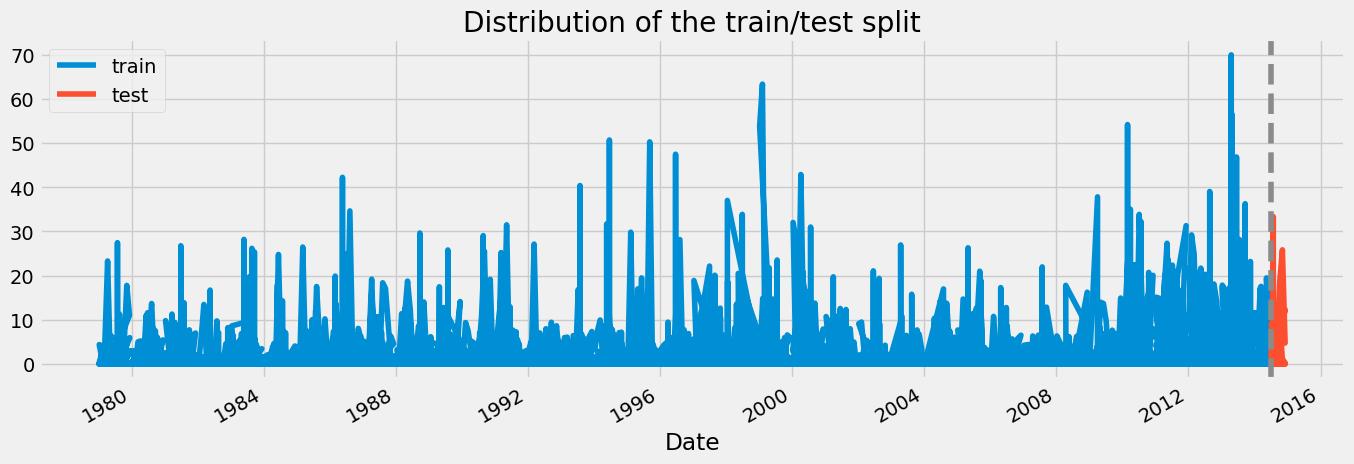

In [30]:
fig, ax = plt.subplots(figsize = (15, 5))
tr.plot(ax = ax, label = "Training", title = "Distribution of the train/test split")
te.plot(ax = ax, label = "Testing")
ax.axvline('2014-7-02', color = color_pallete[4], ls = '--')
ax.legend(['train','test'])
plt.show()

In [13]:
def feature_extraction(df):
    df = df.copy()
    
    
    df['dayofweek'] = df.index.day_of_week
    df['month'] = df.index.month
    df['dayofyear'] = df.index.day_of_year
    df['year'] = df.index.year
    iso = df.index.isocalendar()


    return df
df = feature_extraction(df)

In [15]:
df.columns

Index(['Max Temperature', 'Min Temperature', 'Wind', 'Relative Humidity',
       'Solar', 'Precipitation', 'dayofweek', 'month', 'dayofyear', 'year'],
      dtype='object')

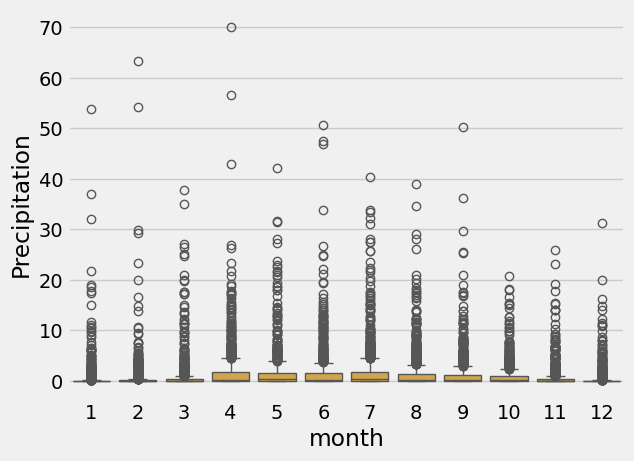

In [16]:
sns.boxplot(data=df, x='month', y = 'Precipitation', color=color_pallete[2])
ax.set_title('Month')
plt.show()

In [17]:
train = feature_extraction(train)
test = feature_extraction(test)

In [18]:
Features  = [ 'Max Temperature', 'Min Temperature', 'Wind', 'Relative Humidity',
       'Solar', 'dayofweek',  'month', 'dayofyear',
       'year']
Target = 'Precipitation'

In [19]:
X_train = train[Features]
Y_train = train[Target]
X_test = test[Features]
Y_test = test[Target]

In [20]:
X_train.shape, Y_train.shape, X_test.shape, Y_test.shape

((12927, 9), (12927,), (60, 9), (60,))

In [21]:
regression = xgb.XGBRegressor(n_estimators = 200, early_stopping_rounds = True, learning_rate = 0.001)
regression.fit(X_train, Y_train, eval_set = [(X_train, Y_train), (X_test, Y_test)], verbose = True)

[0]	validation_0-rmse:3.32249	validation_1-rmse:7.66064
[1]	validation_0-rmse:3.32070	validation_1-rmse:7.65750
[2]	validation_0-rmse:3.31892	validation_1-rmse:7.65432
[3]	validation_0-rmse:3.31714	validation_1-rmse:7.65119
[4]	validation_0-rmse:3.31536	validation_1-rmse:7.64802
[5]	validation_0-rmse:3.31358	validation_1-rmse:7.64489
[6]	validation_0-rmse:3.31180	validation_1-rmse:7.64174
[7]	validation_0-rmse:3.31003	validation_1-rmse:7.63861
[8]	validation_0-rmse:3.30826	validation_1-rmse:7.63546
[9]	validation_0-rmse:3.30649	validation_1-rmse:7.63231
[10]	validation_0-rmse:3.30472	validation_1-rmse:7.62920
[11]	validation_0-rmse:3.30296	validation_1-rmse:7.62606
[12]	validation_0-rmse:3.30120	validation_1-rmse:7.62296
[13]	validation_0-rmse:3.29944	validation_1-rmse:7.61982
[14]	validation_0-rmse:3.29768	validation_1-rmse:7.61673
[15]	validation_0-rmse:3.29593	validation_1-rmse:7.61359
[16]	validation_0-rmse:3.29418	validation_1-rmse:7.61050
[17]	validation_0-rmse:3.29242	validation

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,True
,enable_categorical,True
,eval_metric,None


In [22]:
feature_stat = pd.DataFrame(data = regression.feature_importances_, 
             index= regression.feature_names_in_,
            columns = ['importance'])

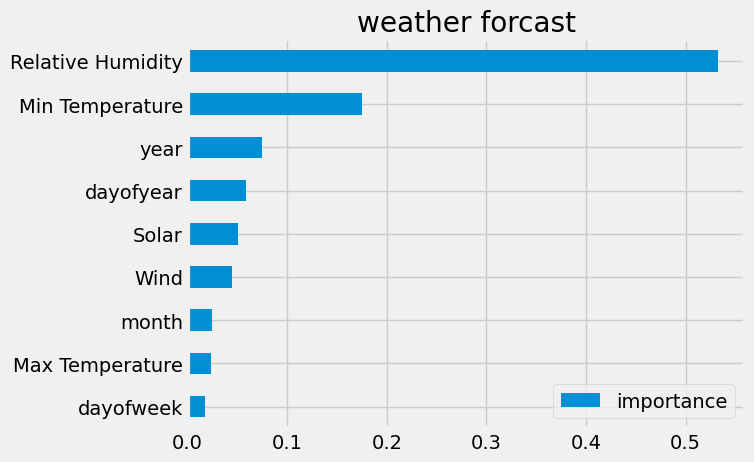

In [23]:
feature_stat.sort_values('importance').plot(kind = 'barh', title = 'weather forcast')
plt.show()

In [24]:
test['Prediction'] = regression.predict(X_test)

In [25]:
test

,Max Temperature,Min Temperature,Wind,Relative Humidity,Solar,Precipitation,dayofweek,month,dayofyear,year,Prediction
Date,,,,,,,,,,,
2014-08-01,32.521,14.128,1.261902,0.461411,24.019660,0.000000,4,8,213,2014,0.961477
2014-09-01,31.257,14.319,1.476756,0.561609,17.690377,0.099564,0,9,244,2014,0.980360
2014-10-01,32.095,15.044,1.401816,0.503281,22.825782,0.048065,2,10,274,2014,0.971144
2014-11-01,32.761,12.630,1.490344,0.453660,25.939256,0.000000,5,11,305,2014,0.961477
2014-12-01,29.609,12.387,1.588361,0.426592,25.410203,0.000000,0,12,335,2014,0.954681
2014-07-02,32.737,16.417,1.090291,0.549299,18.772779,2.023888,2,7,183,2014,1.027750
2014-08-02,29.769,16.247,1.084452,0.635666,11.591852,7.044980,5,8,214,2014,1.113235
2014-09-02,33.613,13.252,1.151467,0.596972,23.879885,0.000000,1,9,245,2014,1.001063
2014-10-02,31.108,14.483,1.753840,0.547500,25.673681,0.000000,3,10,275,2014,0.975558
